In [2]:
import torch

autograd의 기본 흐름
1.미분할 텐서에 requires_grad = True 설정
2.해당 텐서를 사용하여 연산수행
3.결과 텐서에 backward()실행.
4.원본 텐서의 grad속성에서 미분값 확인

requires_grad
-True : 해당 텐서에 대한 연산을 추적하여 기울기를 계산할 수 있도록 설정.
-False : 기본값, 해당 텐서에 대한 연산을 추적하지 않음.
- 일반적으로 모델이 학습해야 하는 가중치(weight)와 편향(bias)에 True 를 설정함

In [5]:
x = torch.tensor(1.0, requires_grad=True)
print(x)
print(x.requires_grad)

x.requires_grad = True 

tensor(1., requires_grad=True)
True


In [7]:
x = torch.tensor([1.0], requires_grad=True)
y = x**2
print(y)
y.backward()
print(y)
print(x.grad)

tensor([1.], grad_fn=<PowBackward0>)
tensor([1.], grad_fn=<PowBackward0>)
tensor([2.])


In [9]:
x = torch.tensor(1.0,requires_grad = True)
x.requires_grad = False 
    #transfer learning할 때 사용
    #내가 만들어 놓은 학습된 모델에서 일부분만 학습 시키고 싶을 때 
y = x**2
print(y)
# y.backward()


tensor(1.)


In [10]:
x = torch.tensor([2.0,4.0], requires_grad = True)
y = x*3

print(x.requires_grad)
print(y.requires_grad)
print(y.is_leaf)
print(y.is_leaf)
print(y.grad_fn)

True
True
False
False


연쇄법칙(chain rule)
함수가 여러 연산으로 연결되어 있으면 각 연산의 미분값을 연쇄적으로 곱하여 최종 기울기를 계산함

In [14]:
x = torch.tensor(1.0, requires_grad=True)
y = x**2
print(y)

z = 3*y
print(z)

z.backward()
print(x.grad)
print(y.grad)

tensor(1., grad_fn=<PowBackward0>)
tensor(3., grad_fn=<MulBackward0>)
tensor(6.)
None


C:\Users\mega\AppData\Local\Temp\ipykernel_10488\214403220.py:10: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:493.)
  print(y.grad)


In [15]:
#중간에 있는 y의 미분값도 알고 싶다면 
x = torch.tensor(1., requires_grad=True)
y = x**2
y.retain_grad()

z = 3*y
z.backward()
print(x.grad)
print(y.grad)

tensor(6.)
tensor(3.)


In [18]:
x = torch.tensor(1.,requires_grad=True)
y = x**2
z = 3*y

y.backward()    #y부터 미분 시작(z제외)
print(x.grad)

tensor(2.)


In [20]:
x = torch.tensor(1., requires_grad=True)
a = x**2
b = a+1

print(b)

c = b**2
c.backward()
print(x.grad)

tensor(2., grad_fn=<AddBackward0>)
tensor(8.)


3.편미분
:함수에 여러 변수가 있을 때는 각 변수에 대해 따로 미분할 수 있음.

In [23]:
x = torch.tensor(1., requires_grad=True)
y = torch.tensor(1., requires_grad=True)

z = 2*x**2 + y**2
print(z)

z.backward()
print(x.grad)
print(y.grad)

tensor(3., grad_fn=<AddBackward0>)
tensor(4.)
tensor(2.)


In [24]:
x = torch.tensor(2., requires_grad=True)
y = torch.tensor(3., requires_grad=True)

f = x**2 + 2*x*y + y**2
f.backward()

print(x.grad)
print(y.grad)


tensor(10.)
tensor(10.)


4. 벡터 출력의 기울기 계산 
y.sum().backward()
y.backward(torch.ones_like(y))

In [30]:
x = torch.tensor([1., 2, 3], requires_grad=True)
y = torch.sum(x**2)
print(y)

y.backward()
print(y)
print(x.grad)

x = torch.tensor([1., 2, 3], requires_grad=True)
y = x**2
y.sum().backward()

print(y)
print(x.grad)

x = torch.tensor([1., 2, 3], requires_grad=True)
y = x**2
y.backward(torch.ones_like(y))

tensor(14., grad_fn=<SumBackward0>)
tensor(14., grad_fn=<SumBackward0>)
tensor([2., 4., 6.])
tensor([1., 4., 9.], grad_fn=<PowBackward0>)
tensor([2., 4., 6.])


Gradient 누적과 초기화
: backward()를 여러번 실행하면 grad에 새로운 기울기가 더해짐 
-기울기를 새로 계산하려면 기존 기울기를 0으로 초기화
- x.grad.zero_()
- 모델 학습에서는 일반적으로 optimizer.zero_grad()를 사용함 

In [36]:
x = torch.tensor([1.,2,3], requires_grad=True)
y = (x**2).sum()
y.backward()
print(x.grad)

z = (3*x).sum()
z.backward()
print(x.grad)

x.grad.zero_()
print(x.grad)

w = (x**3).sum()
w.backward()
print(x.grad)

tensor([2., 4., 6.])
tensor([5., 7., 9.])
tensor([0., 0., 0.])
tensor([ 3., 12., 27.])


torch.autograd.grad()
: 지정한 입력텐서에 대한 기울기 (미분값)을 반환하는 함수.

- backward() : 계산한 기울기를 입력텐서의 .grad에 누적 
- torch.autograd.grad() : 기울기를 반환해줌. 기본적으로 .grad에 누적하지 않음 

-언제 사용
1. 특정 변수의 미분값만 필요할 때 
2. 기울기를 .grad 에 저장하고 싶지 않을 때 
3. 여러 변수를 편미분을 동시에 구할 때 : 여러 입력변수의 기울기를 튜플로 반환 받을 수 있음 

사용 형식
torch.autograd.grad(outputs, inputs)

In [5]:
x = torch.tensor(4., requires_grad=True)
y = x**3 

gradient = torch.autograd.grad(y,x)

print( y)
print(gradient )
print(x.grad)

tensor(64., grad_fn=<PowBackward0>)
(tensor(48.),)
None


7. detach()
requires_grad = True인 텐서에 연산을 적용하면 pytorch는 연산과정을 추적함. <br>
그런데 특정 텐서부터는 더이상 gradient를 계산하지 않도록 하고 싶을 때 detach()를 사용 
** 기존 텐서와 값은 공유하지만, 자동 미분 계산 그래프에서 분리된 텐서를 반환 

- 원본 텐서의 연산 추적은 그대로 유지됨
- 분리된 텐서는 해당 연산 그래프를 통한 기울기 계산에 연결되지 않음 
- 학습 결과를 출력하거나 numpy로 변환할 때 자주 사용함. 

In [9]:
x = torch.tensor([1.,2,3],requires_grad=True)
y = x*2
y_detach = y.detach()

print(y)
print(y.requires_grad)
print(y_detach)
print(y_detach.requires_grad)
print(y_detach.grad_fn)

tensor([2., 4., 6.], grad_fn=<MulBackward0>)
True
tensor([2., 4., 6.])
False
None


In [10]:
# 변수의 값을 그냥 상수로 사용하고 싶을 때 

x = torch.tensor(1., requires_grad=True)
y = x**2
z = y.detach()

w = y+z  #x**2 + 1
w.backward()
print(x.grad)

tensor(2.)


8. torch.no_grad()
: 지정한 블록 코드 안에서는 자동 미분을 위한 연산추적을 비활성화함

- 학습 중 모델의 가중치를 업데이트할 때 
- 검증 및 예측 처럼 기울기 계산이 필요하지 않을 때 
- 불필요한 계산 그래프 생성을 줄여 메모리 사용량을 줄일 수 있음 

[사용형식]
'''python
with torch.no_grad() : 
    # 기울기를 추적하지 않은 연산
'''
-detach()는 특정 텐서를 계산 그래프에서 분리하고, no_grad() 는 특정 코드블록의 연산 추적을 막는다는 차이가 있음 

In [11]:
%pip install torchviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import torch
from torchviz import make_dot



In [2]:
# 1. 입력 텐서(리프 노드) 정의
x = torch.tensor([2.0], requires_grad=True)

# 2. 연산을 수행하여 연산 그래프 구축
y = x ** 2
z = y + 3

# 3. 최종 결과 텐서(z)를 make_dot에 전달
# params 인수를 통해 변수 이름을 텐서 객체와 매핑합니다.
dot = make_dot(z, params={'x': x})

# 4. 파일로 렌더링 및 저장
dot.render("computation_graph", format="png")

'computation_graph.png'

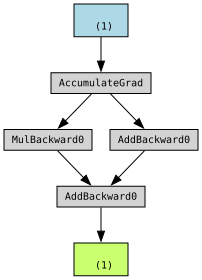

In [3]:
x = torch.tensor([1.],requires_grad=True)
make_dot(x)
make_dot(x**2+1)
make_dot((x**2+1)**2)

y = 2*x
z = 3+x
r=y+z
make_dot(r)